# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [1]:
import nltk
import string
from nltk.corpus import gutenberg

In [2]:
#1. Cargando textos originasles 
nltk.download('gutenberg')
nltk.download('punkt')
fileids = gutenberg.fileids()
print(f"Número de documentos en el corpus pequeño: {len(fileids)}")

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\david\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\david\AppData\Roaming\nltk_data...


Número de documentos en el corpus pequeño: 18


[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\david\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [3]:
#2. Identifica el número de documentos y su tamaño
doc_sizes = {fileid: len(gutenberg.raw(fileid)) for fileid in fileids}
for fid, size in doc_sizes.items():
    print(f"- {fid}: {size} caracteres")

- austen-emma.txt: 887071 caracteres
- austen-persuasion.txt: 466292 caracteres
- austen-sense.txt: 673022 caracteres
- bible-kjv.txt: 4332554 caracteres
- blake-poems.txt: 38153 caracteres
- bryant-stories.txt: 249439 caracteres
- burgess-busterbrown.txt: 84663 caracteres
- carroll-alice.txt: 144395 caracteres
- chesterton-ball.txt: 457450 caracteres
- chesterton-brown.txt: 406629 caracteres
- chesterton-thursday.txt: 320525 caracteres
- edgeworth-parents.txt: 935158 caracteres
- melville-moby_dick.txt: 1242990 caracteres
- milton-paradise.txt: 468220 caracteres
- shakespeare-caesar.txt: 112310 caracteres
- shakespeare-hamlet.txt: 162881 caracteres
- shakespeare-macbeth.txt: 100351 caracteres
- whitman-leaves.txt: 711215 caracteres


In [4]:
#3. Función de preprocesamiento consistente
def preprocess_text(text):
    # Conversión a minúsculas
    text = text.lower()
    # Eliminación de puntuación usando las tablas de traducción de python
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Tokenización por espacios en blanco (separación básica de tokens)
    tokens = text.split()
    return tokens

#Generar el corpus preprocesado (diccionario de ID de documento -> lista de tokens)
corpus_tokens = {fileid: preprocess_text(gutenberg.raw(fileid)) for fileid in fileids}
print("\n¡Preprocesamiento completado para el corpus pequeño!")


¡Preprocesamiento completado para el corpus pequeño!


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [5]:
def busqueda_secuencial(query, corpus):
    """
    Realiza una búsqueda secuencial utilizando estrictamente dos bucles for anidados:
    el primero recorre los documentos y el segundo los tokens de cada documento.
    """
    matching_docs = []
    normalized_query = query.lower().strip() #minuscula y sin espacio 
    
    # Primer bucle recorre los documentos
    for doc_id, tokens in corpus.items():
        found = False
        # Segundo bucle recorre los tokens de cada documento
        for token in tokens:
            if token == normalized_query:
                found = True
                break # Encontrado en este documento, pasamos al siguiente
        if found:
            matching_docs.append(doc_id)
            
    return matching_docs

# Pruebas con términos frecuentes, poco frecuentes e inexistentes
print("Término frecuente ('the'):", busqueda_secuencial("the", corpus_tokens)[:5], "... (mostrando primeros resultados)")
print("Término poco frecuente ('monstrous'):", busqueda_secuencial("monstrous", corpus_tokens))
print("Término inexistente ('xyzabc123'):", busqueda_secuencial("xyzabc123", corpus_tokens))

Término frecuente ('the'): ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt'] ... (mostrando primeros resultados)
Término poco frecuente ('monstrous'): ['austen-sense.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
Término inexistente ('xyzabc123'): []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [6]:
import time

def medir_tiempo_secuencial(query, corpus, iterations=30):
    """
    Mide el tiempo medio de ejecución de 30 iteraciones de la búsqueda secuencial.
    Registra el resultado en milisegundos.
    """
    start_time = time.perf_counter_ns()
    for _ in range(iterations):
        _ = busqueda_secuencial(query, corpus)
    end_time = time.perf_counter_ns()
    
    total_time_ms = (end_time - start_time) / 1_000_000.0
    mean_time_ms = total_time_ms / iterations
    return mean_time_ms

terms_test = ["the", "whale", "monstrous", "xyzabc123"]
for term in terms_test:
    mean_t = medir_tiempo_secuencial(term, corpus_tokens)
    print(f"Búsqueda secuencial para '{term}': {mean_t:.4f} ms (promedio de 30 ejecuciones)")

Búsqueda secuencial para 'the': 0.0229 ms (promedio de 30 ejecuciones)
Búsqueda secuencial para 'whale': 51.6102 ms (promedio de 30 ejecuciones)
Búsqueda secuencial para 'monstrous': 38.0816 ms (promedio de 30 ejecuciones)
Búsqueda secuencial para 'xyzabc123': 52.5095 ms (promedio de 30 ejecuciones)


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [7]:
class IndiceInvertido:
    def __init__(self, corpus):
        self.index = {}
        self.doc_ids = list(corpus.keys())
        self._build(corpus)
        
    def _build(self, corpus):
        for doc_id, tokens in corpus.items():
            # Usamos un conjunto por documento para registrar la frecuencia documental (DF) de forma única por doc
            unique_tokens = set(tokens)
            for token in unique_tokens:
                if token not in self.index:
                    self.index[token] = []
                self.index[token].append(doc_id)
                
    def get_postings(self, term):
        return self.index.get(term.lower(), [])
    
    def document_frecuencia(self, term):
        return len(self.get_postings(term))

# Construir el índice
indice_inv = IndiceInvertido(corpus_tokens)

# Inspeccionar DF de varios términos
terms = ["god", "captain", "whale", "gutenberg"]
for t in terms:
    print(f"Frecuencia Documental (DF) de '{t}': {indice_inv.document_frecuencia(t)}")

# Consultas booleanas (AND, OR, NOT)
def consulta_boolean(query_str, index):
    """
    Soporta consultas simples o expresiones booleanas básicas:
    Ejemplos: 'whale', 'whale AND captain', 'whale OR captain', 'NOT whale'
    """
    tokens = query_str.lower().split()
    all_docs = set(index.doc_ids)
    
    if len(tokens) == 1:
        return set(index.get_postings(tokens[0]))
    
    if len(tokens) == 2 and tokens[0] == 'not':
        return all_docs - set(index.get_postings(tokens[1]))
        
    if len(tokens) == 3:
        term1, op, term2 = tokens[0], tokens[1].upper(), tokens[2]
        set1 = set(index.get_postings(term1))
        set2 = set(index.get_postings(term2))
        
        if op == 'AND':
            return set1.intersection(set2)
        elif op == 'OR':
            return set1.union(set2)
            
    return set()

print("\nResultados Consulta Booleana ('whale AND captain'):", consulta_boolean("whale AND captain", indice_inv))

Frecuencia Documental (DF) de 'god': 16
Frecuencia Documental (DF) de 'captain': 9
Frecuencia Documental (DF) de 'whale': 6
Frecuencia Documental (DF) de 'gutenberg': 1

Resultados Consulta Booleana ('whale AND captain'): {'whitman-leaves.txt', 'bible-kjv.txt', 'melville-moby_dick.txt', 'bryant-stories.txt'}


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [8]:
def tiempo_medio(query_str, index, iterations=30):
    start_time = time.perf_counter_ns()
    for _ in range(iterations):
        _ = consulta_boolean(query_str, index)
    end_time = time.perf_counter_ns()
    return ((end_time - start_time) / 1_000_000.0) / iterations

test_queries = ["whale", "monstrous", "captain"]
print(f"{'Consulta':<12} | {'Seq Docs':<15} | {'Index Docs':<15} | {'Seq Time (ms)':<15} | {'Index Time (ms)':<15}")
print("-" * 80)

for q in test_queries:
    # Secuencial
    secuencial_docs = set(busqueda_secuencial(q, corpus_tokens))
    secuencial_time = medir_tiempo_secuencial(q, corpus_tokens)
    
    # Índice Invertido
    inv_indx_docs = consulta_boolean(q, indice_inv)
    inv_indx_time = tiempo_medio(q, indice_inv)
    
    match_status = secuencial_docs == inv_indx_docs
    print(f"{q:<12} | {str(len(secuencial_docs)):<15} | {str(len(inv_indx_docs)):<15} | {secuencial_time:<15.4f} | {inv_indx_time:<15.4f} (Iguales: {match_status})")

Consulta     | Seq Docs        | Index Docs      | Seq Time (ms)   | Index Time (ms)
--------------------------------------------------------------------------------
whale        | 6               | 6               | 33.3421         | 0.0013          (Iguales: True)
monstrous    | 10              | 10              | 38.3851         | 0.0018          (Iguales: True)
captain      | 9               | 9               | 16.8347         | 0.0014          (Iguales: True)


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [9]:
import os
import glob
import urllib.request
import zipfile
import tarfile

In [10]:

# ruta
extracted_dir = "cache/epub"

# Búsqueda recursiva de todos los archivos .txt dentro de las subcarpetas numéricas
all_txt_files = glob.glob(os.path.join(extracted_dir, "**", "*.txt"), recursive=True)

print(f"Cantidad total de libros (.txt) encontrados: {len(all_txt_files)}")

Cantidad total de libros (.txt) encontrados: 7378


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [11]:
# Cargar un subconjunto manejable de prueba del corpus grande
subset_files = all_txt_files[:1000]
grande_corpus_tokens = {}

for path in subset_files:
    doc_id = os.path.basename(path)
    try:
        with open(path, 'r', encoding='utf-8', errors='ignore') as f:
            content = f.read()
            grande_corpus_tokens[doc_id] = preprocess_text(content)
    except Exception as e:
        continue

print(f"Documentos válidos cargados en memoria para pruebas: {len(grande_corpus_tokens)}")

#Idx invertido sobre el corpus grande
grande_index = IndiceInvertido(grande_corpus_tokens)
query_test = "the"

sec_t = medir_tiempo_secuencial(query_test, grande_corpus_tokens, iterations=5)
idx_t = tiempo_medio(query_test, grande_index, iterations=30)

print(f"Tiempo secuencial promedio (corpus grande): {sec_t:.4f} ms")
print(f"Tiempo con índice invertido promedio (corpus grande): {idx_t:.4f} ms")

Documentos válidos cargados en memoria para pruebas: 1000
Tiempo secuencial promedio (corpus grande): 1.4290 ms
Tiempo con índice invertido promedio (corpus grande): 0.0994 ms


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

Tamaño n = 50 docs | Tokens: 4131888 | Sec: 0.01 ms | Index: 0.0039 ms
Tamaño n = 100 docs | Tokens: 7318207 | Sec: 0.05 ms | Index: 0.0440 ms
Tamaño n = 250 docs | Tokens: 18990234 | Sec: 0.09 ms | Index: 0.0473 ms
Tamaño n = 500 docs | Tokens: 35727766 | Sec: 0.39 ms | Index: 0.0996 ms


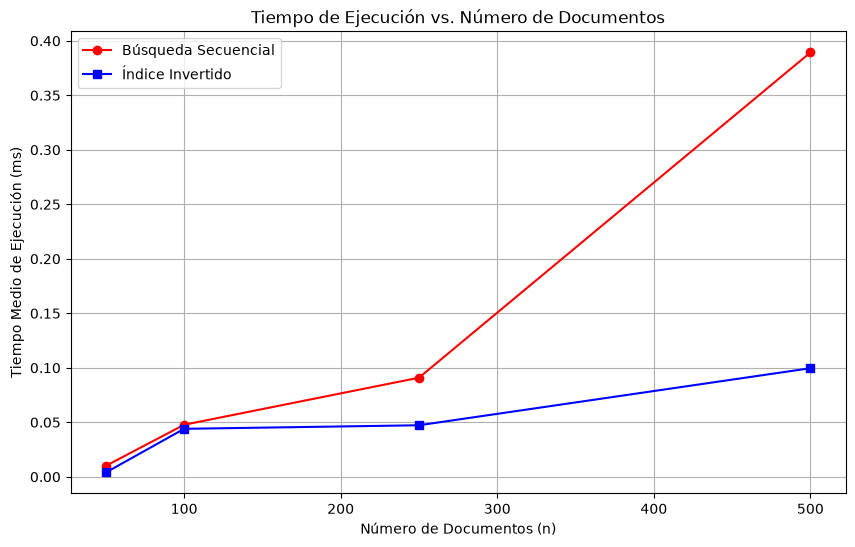

In [ ]:
import matplotlib.pyplot as plt

# Definir tamaños crecientes del corpus
tamaños_del_test = [50, 100, 250, 500] 
#no superar el total de archivos disponibles
tamaños_del_test = [s for s in tamaños_del_test if s <= len(all_txt_files)]

sec_times = []
idx_times = []
total_tokens_list = []

query_bench = "the"

for n in tamaños_del_test:
    # subconjunto de tamaño n
    sub_files = all_txt_files[:n]
    sub_corpus = {}
    total_tokens = 0
    
    for path in sub_files:
        doc_id = os.path.basename(path)
        try:
            with open(path, 'r', encoding='utf-8', errors='ignore') as f:
                tokens = preprocess_text(f.read())
                sub_corpus[doc_id] = tokens
                total_tokens += len(tokens)
        except:
            continue
            
    total_tokens_list.append(total_tokens)
    
    # Medir búsqueda secuencial (n es mediano para optimizar tiempo)
    it_sec = 10 if n <= 250 else 3
    t_sec = medir_tiempo_secuencial(query_bench, sub_corpus, iterations=it_sec)
    sec_times.append(t_sec)
    
    # Construir índice y medir
    sub_index = IndiceInvertido(sub_corpus)
    t_idx = tiempo_medio(query_bench, sub_index, iterations=30)
    idx_times.append(t_idx)
    
    print(f"Tamaño n = {n} docs | Tokens: {total_tokens} | Sec: {t_sec:.2f} ms | Index: {t_idx:.4f} ms")

# Gráfica del tiempo medio en función del número de documentos
plt.figure(figsize=(10, 6))
plt.plot(tamaños_del_test, sec_times, marker='o', label='Búsqueda Secuencial', color='red')
plt.plot(tamaños_del_test, idx_times, marker='s', label='Índice Invertido', color='blue')
plt.title('Tiempo de Ejecución vs. Número de Documentos')
plt.xlabel('Número de Documentos (n)')
plt.ylabel('Tiempo Medio de Ejecución (ms)')
plt.legend()
plt.grid(True)
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

--- Ajuste Búsqueda Secuencial ---
Función: t(n) = 0.0008 * n + -0.0521
Coeficiente R^2: 0.9381

--- Ajuste Índice Invertido ---
Función: t(n) = 0.0002 * n + 0.0076
Coeficiente R^2: 0.8854


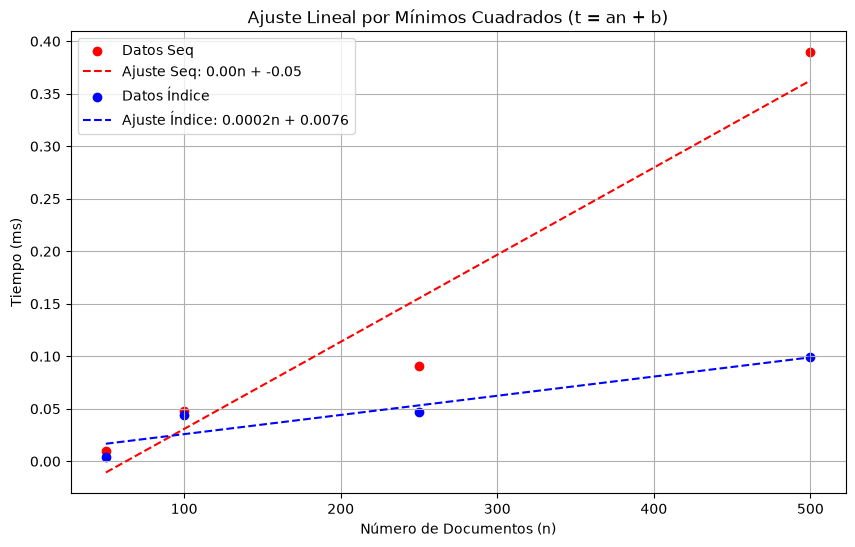

In [ ]:
import numpy as np

# Ajuste lineal por mínimos cuadrados: t(n) = an + b
n_array = np.array(tamaños_del_test, dtype=float)

# Ajuste para Búsqueda Secuencial
seq_times_arr = np.array(sec_times)
a_sec, b_sec = np.polyfit(n_array, seq_times_arr, 1)
p_seq = np.poly1d([a_sec, b_sec])
r2_seq = 1 - (np.sum((seq_times_arr - p_seq(n_array))**2) / np.sum((seq_times_arr - np.mean(seq_times_arr))**2))

# Ajuste para Índice Invertido
idx_times_arr = np.array(idx_times)
a_idx, b_idx = np.polyfit(n_array, idx_times_arr, 1)
p_idx = np.poly1d([a_idx, b_idx])
r2_idx = 1 - (np.sum((idx_times_arr - p_idx(n_array))**2) / np.sum((idx_times_arr - np.mean(idx_times_arr))**2))

print(f"--- Ajuste Búsqueda Secuencial ---")
print(f"Función: t(n) = {a_sec:.4f} * n + {b_sec:.4f}")
print(f"Coeficiente R^2: {r2_seq:.4f}\n")

print(f"--- Ajuste Índice Invertido ---")
print(f"Función: t(n) = {a_idx:.4f} * n + {b_idx:.4f}")
print(f"Coeficiente R^2: {r2_idx:.4f}")

# Gráfica comparativa de las funciones ajustadas
plt.figure(figsize=(10, 6))
plt.scatter(n_array, seq_times_arr, color='red', label='Datos Sec')
plt.plot(n_array, p_seq(n_array), color='red', linestyle='--', label=f'Ajuste Seq: {a_sec:.2f}n + {b_sec:.2f}')

plt.scatter(n_array, idx_times_arr, color='blue', label='Datos Índice')
plt.plot(n_array, p_idx(n_array), color='blue', linestyle='--', label=f'Ajuste Índice: {a_idx:.4f}n + {b_idx:.4f}')

plt.title('Ajuste Lineal por Mínimos Cuadrados (t = an + b)')
plt.xlabel('Número de Documentos (n)')
plt.ylabel('Tiempo (ms)')
plt.legend()
plt.grid(True)
plt.show()

#### **Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.**

Búsqueda Secuencial: Su complejidad temporal teórica es de $O(D \times L)$, donde $D$ es el número de documentos y $L$ es la longitud promedio de tokens por documento. Al crecer el corpus linealmente, el tiempo aumenta de forma directa, lo cual se alinea con una tendencia de crecimiento lineal en la gráfica.

Índice Invertido: Una vez construido el índice, la consulta opera teóricamente con una complejidad cercana a $O(1)$ o dependiente únicamente del tamaño de la lista de postings del término buscado, mostrando una pendiente casi horizontal y tiempos de respuesta drásticamente menores en comparación con la búsqueda secuencial a medida que escala el corpus.

## Acuerdo de uso de inteligencia artificial

Declaro que recurrí a la inteligencia artificial como apoyo para evaluar la estructura del notebook,aumentar la velocidad de escritura, reconocer posibles inconsistencias entre las indicaciones y el código, plantear ajustes que favorezcan la reproducibilidad y mejorar la redacción del análisis escrito. No obstante, esta herramienta no reemplaza mi criterio ni mi responsabilidad académica. Es mi deber revisar las sugerencias, ejecutar el notebook, verificar los resultados obtenidos, comprender los algoritmos implementados y referenciar las fuentes externas consultadas. Asumo la autoría y responsabilidad del trabajo final, evitando presentar como comprobados resultados que no haya validado personalmente.

**Justificación:** La IA se utilizó como recurso de asistencia técnica y de redacción para identificar errores y precisar las limitaciones de las mediciones. La interpretación considera los resultados registrados y la complejidad teórica de los algoritmos, sin inventar datos sobre el consumo de memoria RAM o el almacenamiento temporal. La ejecución definitiva deberá realizarse en el entorno previsto para la entrega, con el propósito de confirmar el funcionamiento y la validez de los resultados.